# Four harder tests

The first notebook tested a claim with four tidy, ready-made datasets: global and US temperature as one number per
year, CO₂ emissions, and radiative forcing. It ended with a list of what it had *not* done. This notebook does those
four things:

1. **Stations.** Go back to the thermometers themselves: about 27,000 weather stations, raw and corrected, and
   rebuild the averages ourselves, including from the very stations the original study used.
2. **El Niño.** Remove the warm and cold swings of the tropical Pacific, the largest source of year-to-year noise
   in global temperature, and see whether the long trends change.
3. **Uncertainty of the record.** The Met Office publishes not one temperature history but 200 equally likely ones.
   Run every trend on all 200.
4. **Climate models.** Compare the observed trends with what 34 full climate models produce from the same forcing.

Each section says what the data is, how to get it, what every processing step does and why, and how to read the
result. Run the cells from the top: later cells use what earlier cells made. The downloads are about 230 MB in
all and are kept in the `data` folder, so the second run is fast.

In [1]:
import io
import json
import tarfile
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data")
DATA.mkdir(exist_ok=True)
WINDOWS = [(1857, 1898), (1899, 1940), (1941, 1982), (1983, 2024)]
t_start = time.time()


def get(name, url):
    """Download url to data/name once; afterwards reuse the saved file."""
    target = DATA / name
    if not target.exists():
        req = urllib.request.Request(url, headers={"User-Agent": "climate-data-notebook/1.0"})
        target.write_bytes(urllib.request.urlopen(req, timeout=600).read())
    return target


def trend(years, values):
    """Least-squares slope in °C per decade, and its standard error corrected for autocorrelation (see notebook 1)."""
    years, values = np.asarray(years, float), np.asarray(values, float)
    ok = ~np.isnan(values)
    x, y = years[ok] - years[ok].mean(), values[ok]
    n = len(y)
    b = (x * y).sum() / (x * x).sum()
    resid = y - y.mean() - b * x
    r1 = np.corrcoef(resid[:-1], resid[1:])[0, 1]
    n_eff = n * (1 - r1) / (1 + r1) if r1 > 0 else n
    se = np.sqrt((resid ** 2).sum() / (n - 2) / (x * x).sum()) * np.sqrt((n - 2) / max(n_eff - 2, 1))
    return 10 * b, 10 * se


print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.0.1 | pandas 2.2.3


`trend` is the function from the first notebook, written compactly. It returns two numbers: the slope of the
straight line through the years, in °C per decade, and its standard error. The error is widened because
neighbouring years resemble each other (a warm year tends to follow a warm year), so 42 years carry less
independent information than 42 separate coin tosses would. The first notebook explains this in detail.

# Test 1: back to the stations

## What a station record is

A weather station is a thermometer in a ventilated white box about 1.5 m above grass. Someone, or later a machine,
reads the highest and lowest temperature of each day. Averaged over a month, those readings become one number per
station per month. NOAA collects them from every country into the **Global Historical Climatology Network**.
Its daily archive (GHCN-Daily) is what the study we are checking used. Its monthly archive (GHCN-Monthly, version 4)
is built from the same stations and comes in two versions:

- **QCU, "quality controlled, unadjusted"**: the readings as reported, with only impossible values removed. We call
  this *raw*.
- **QCF, "quality controlled, adjusted"**: the same readings after **homogenisation**. We call this *homogenised*.

## Why records need correcting

A long record is rarely made with the same thermometer, in the same place, read at the same hour. Over a century a
station may move from a rooftop in town to an airfield, swap a mercury thermometer in a wooden screen for an
electronic sensor in a small plastic one, or change the hour at which the daily maximum and minimum are reset.
Each change shifts the readings by a few tenths of a degree, up or down, overnight. That shift is not climate,
but a trend line cannot tell the difference.

The US is a well-known case. Volunteer observers used to reset their thermometers in the late afternoon, and over
the twentieth century most switched to the morning. An afternoon reset counts a hot afternoon twice (once
in each day's maximum); a morning reset counts a cold morning twice. The switch made US records read cooler,
by about 0.3 °C, after the change. Uncorrected, it hides part of the real warming.

NOAA's **Pairwise Homogenisation Algorithm** finds such shifts without needing to know their cause: it compares
each station with its neighbours, which share the same weather. A sudden, lasting step in the *difference* between
a station and many neighbours, at one station only, marks a change at that station; the record is corrected by the
size of the step.

## Download

Each version is one compressed archive of about 45 MB holding two text files: `.dat` with the temperatures and
`.inv`, the inventory, with each station's position.

In [2]:
GHCNM = "https://www.ncei.noaa.gov/pub/data/ghcn/v4/ghcnm.tavg.latest.{}.tar.gz"
for kind in ("qcu", "qcf"):
    p = get(f"ghcnm_{kind}.tar.gz", GHCNM.format(kind))
    with tarfile.open(p) as tar:
        names = [m.name for m in tar.getmembers() if m.isfile()]
    print(kind, f"{p.stat().st_size / 1e6:.0f} MB", [n.split("/")[-1] for n in names])

qcu 46 MB ['ghcnm.tavg.v4.0.1.20261116.qcu.dat', 'ghcnm.tavg.v4.0.1.20261116.qcu.inv']


qcf 44 MB ['ghcnm.tavg.v4.0.1.20261116.qcf.dat', 'ghcnm.tavg.v4.0.1.20261116.qcf.inv']


## Read a fixed-width file

The `.dat` file is **fixed-width** text: each value sits at fixed character positions, not between commas. One line
holds one station-year. Let us look at one line before parsing millions.

In [3]:
def open_member(kind, ending):
    tar = tarfile.open(DATA / f"ghcnm_{kind}.tar.gz")
    member = next(m for m in tar.getmembers() if m.name.endswith(ending))
    return io.TextIOWrapper(tar.extractfile(member), encoding="ascii")


line = open_member("qcf", ".dat").readline()
print(repr(line[:60]))
print("station id:", line[0:11], "| year:", line[11:15], "| element:", line[15:19])
print("January:", line[19:24], "flags:", repr(line[24:27]), "| February:", line[27:32])

'ACW000116041961TAVG  -71  k  254  k  490  k  791  k 1146  k '
station id: ACW00011604 | year: 1961 | element: TAVG
January:   -71 flags: '  k' | February:   254


Reading the line from left to right:

- characters 1-11: the **station identifier**. The first two letters are the country (`US`, `IN`, `AS` for
  Australia ...). The identifiers are the same as in GHCN-Daily, which lets us find the study's own stations later.
- 12-15: the **year**; 16-19: the **element**, here `TAVG`, the monthly mean temperature.
- then 12 blocks of 8 characters, one per month: a 5-character value in **hundredths of a degree Celsius** (so
  `-71` is -0.71 °C) and three single-character flags. The second flag is the **quality-control flag**: blank means
  the value passed every check. `-9999` means missing.

The parser below keeps a station-year only if all 12 months are present and unflagged, because an annual mean that
is missing January is biased warm. It takes a minute per file.

In [4]:
def annual_means(kind):
    cache = DATA / f"ghcnm_{kind}_annual.csv"
    if cache.exists():
        return pd.read_csv(cache)
    rows = []
    for line in open_member(kind, ".dat"):
        values = [int(line[19 + 8 * m: 24 + 8 * m]) for m in range(12)]
        qc = [line[25 + 8 * m] for m in range(12)]
        if -9999 in values or any(f != " " for f in qc):
            continue
        rows.append((line[:11], int(line[11:15]), sum(values) / 1200))      # mean of 12 months, hundredths -> °C
    a = pd.DataFrame(rows, columns=["id", "year", "t"])
    a.to_csv(cache, index=False)
    return a


def inventory(kind):
    return pd.read_fwf(open_member(kind, ".inv"), colspecs=[(0, 11), (12, 20), (21, 30)], names=["id", "lat", "lon"])


raw, hom = annual_means("qcu"), annual_means("qcf")
stations = inventory("qcf")
print(f"raw: {len(raw):,} station-years from {raw.id.nunique():,} stations")
print(f"homogenised: {len(hom):,} station-years from {hom.id.nunique():,} stations")
print(hom.head())

raw: 1,080,972 station-years from 27,805 stations
homogenised: 1,018,591 station-years from 27,686 stations
            id  year         t
0  ACW00011604  1961  8.703333
1  ACW00011604  1962  7.034167
2  ACW00011604  1963  6.824167
3  ACW00011604  1964  7.814167
4  ACW00011604  1965  7.031667


Each row is now one station in one year with its mean temperature. The homogenised file has fewer rows: the
algorithm drops records it cannot check against enough neighbours.

## From temperatures to anomalies

A station on a mountain is colder than one on the coast, and a station that joins the network in 1950 would pull
a simple average up or down just by appearing. So we never average temperatures across stations. We average
**anomalies**: each station's departure from its *own* normal. Here the normal is the station's mean over
1951-1980, and a station needs at least 15 complete years in that period to have one.

An anomaly of +0.5 then means "half a degree warmer than this place used to be", whatever the place.

In [5]:
def anomalies(a):
    base = a[a.year.between(1951, 1980)].groupby("id").t.agg(["mean", "size"])
    base = base.loc[base["size"] >= 15, "mean"]
    a = a[a.id.isin(base.index)].copy()
    a["anom"] = a.t - a.id.map(base)
    return a.merge(stations, on="id")


raw_a, hom_a = anomalies(raw), anomalies(hom)
print(f"stations with a 1951-80 normal: raw {raw_a.id.nunique():,}, homogenised {hom_a.id.nunique():,}")
print(hom_a[hom_a.id == hom_a.id.iloc[0]].tail(3))

stations with a 1951-80 normal: raw 11,225, homogenised 10,624
             id  year         t      anom      lat      lon
42  ACW00011604  2010  6.665833 -1.067958  57.7667  11.8667
43  ACW00011604  2011  9.315833  1.582042  57.7667  11.8667
44  ACW00011604  2012  8.454167  0.720375  57.7667  11.8667


## Two ways to average stations

**Every station equal.** Add the anomalies of all stations reporting in a year and divide by their number. This
is what a regression with one term per station, like the study's, effectively does. Its weakness is geography:
the US has more long-running stations than the rest of the world together, so this average is mostly an average
of the US, which covers less than 2 % of the Earth.

**Area-weighted grid.** Cut the globe into boxes of 5° latitude by 5° longitude. Average the stations inside each
box first, so a box with 200 stations counts the same as a box with one. Then average the boxes, each weighted by
its area. Lines of longitude meet at the poles, so a 5° box near the pole is much smaller than one at the equator;
its area is proportional to the **cosine of its latitude** (1 at the equator, 0.5 at 60°, 0 at the pole).

The function below does both, for any set of stations.

In [6]:
def two_averages(a):
    every_station = a.groupby("year").anom.mean()
    box = a.assign(box_lat=np.floor(a.lat / 5) * 5 + 2.5, box_lon=np.floor(a.lon / 5) * 5 + 2.5)
    boxes = box.groupby(["year", "box_lat", "box_lon"]).anom.mean().reset_index()
    boxes["w"] = np.cos(np.deg2rad(boxes.box_lat))
    gridded = (boxes.anom * boxes.w).groupby(boxes.year).sum() / boxes.w.groupby(boxes.year).sum()
    return pd.DataFrame({"every_station": every_station, "gridded": gridded}).loc[1850:2024]


us = lambda a: a[a.id.str.startswith("US") & a.lat.between(24.5, 49.5) & a.lon.between(-125, -66.5)]
series = {}
for label, a in (("raw", raw_a), ("homogenised", hom_a)):
    for region, sub in (("all land", a), ("contiguous US", us(a))):
        s = two_averages(sub)
        for how in s.columns:
            series[(label, region, how)] = s[how]
print("built", len(series), "series, e.g. homogenised all-land gridded 2020-2024:")
print(series[("homogenised", "all land", "gridded")].tail(5).round(2))

built 8 series, e.g. homogenised all-land gridded 2020-2024:
year
2020    1.64
2021    1.41
2022    1.40
2023    1.78
2024    1.94
Name: gridded, dtype: float64


## The study's own stations

The study selected GHCN-Daily stations that measured both daily maximum and minimum from 1900 or earlier to 2020
or later. NOAA's inventory of the daily archive lists, for every station and element, the first and last year,
so we can rebuild that selection exactly and find the same stations in the monthly file.

In [7]:
inv = pd.read_fwf(get("ghcnd-inventory.txt", "https://www.ncei.noaa.gov/pub/data/ghcn/daily/ghcnd-inventory.txt"),
                  widths=[11, 9, 10, 5, 5, 5], names=["id", "lat", "lon", "element", "first", "last"])
inv = inv[inv.element.isin(["TMAX", "TMIN"])]
per = inv.groupby("id").agg(n=("element", "nunique"), first=("first", "max"), last=("last", "min"))
sample = set(per[(per.n == 2) & (per["first"] <= 1900) & (per["last"] >= 2020)].index)
us_share = np.mean([s.startswith("US") for s in sample])
print(f"study sample rebuilt: {len(sample):,} stations, {100 * us_share:.0f} % in the US")
print(f"found in monthly file: raw {raw_a.id.isin(sample).groupby(raw_a.id).first().sum():,}, "
      f"homogenised {hom_a.id.isin(sample).groupby(hom_a.id).first().sum():,}")
for label, a in (("raw", raw_a), ("homogenised", hom_a)):
    s = two_averages(a[a.id.isin(sample)])
    for how in s.columns:
        series[(label, "study sample", how)] = s[how]

study sample rebuilt: 1,155 stations, 86 % in the US


found in monthly file: raw 1,020, homogenised 983


The inventory gives a slightly different count from the study's 992 stations, because the archive has been
updated since and the study also dropped stations in cleaning; the US share is the same.

## Where the stations are

A map shows the geography problem directly. Each dot is a homogenised station with at least 30 complete years in
the window; red dots are in the US.

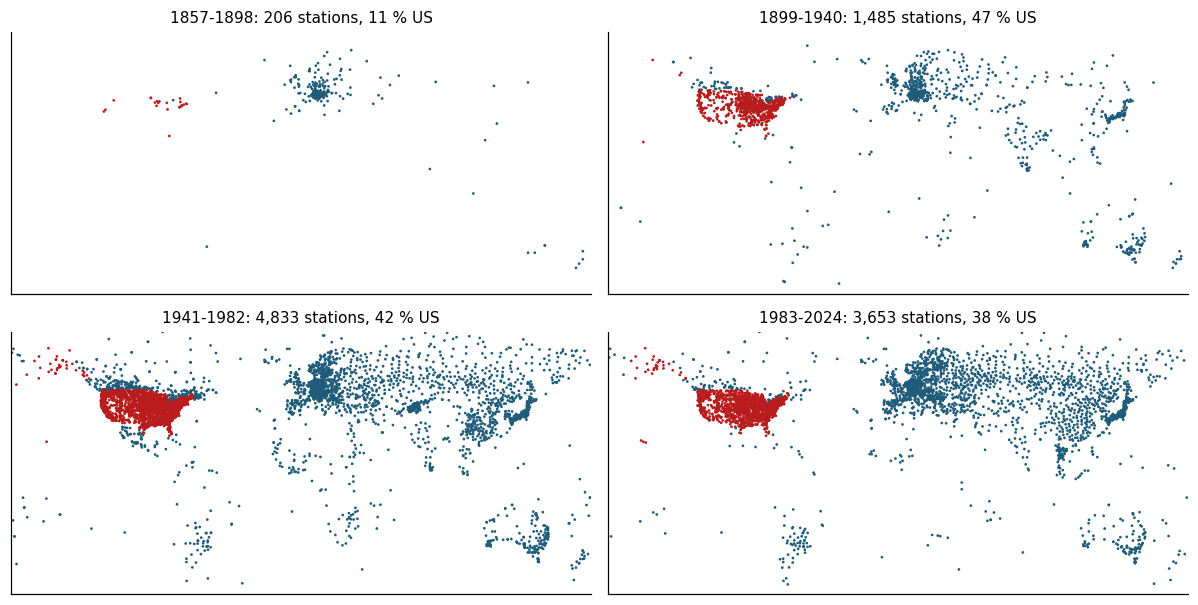

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(11, 5.6))
for ax, (a, b) in zip(axs.flat, WINDOWS):
    n = hom_a[hom_a.year.between(a, b)].groupby("id").size()
    p = stations[stations.id.isin(n[n >= 30].index)]
    is_us = p.id.str.startswith("US")
    ax.scatter(p.lon, p.lat, s=0.6, c=np.where(is_us, "#b91c1c", "#1f5c7a"))
    ax.set(xlim=(-180, 180), ylim=(-60, 80), xticks=[], yticks=[])
    ax.set_title(f"{a}-{b}: {len(p):,} stations, {100 * is_us.mean():.0f} % US", fontsize=10)
plt.tight_layout()
plt.show()

Reading it: in the first two windows almost all long records are in the US and Europe; Africa, South America and
the oceans are nearly empty. An average that treats every station equally is, before 1940, an average of the US.

## The trends, eight ways (and four more)

Now the question of the study: in which 42-year window did temperature rise fastest? We compute the trend of every
series in every window.

In [9]:
rows = []
for (label, region, how), s in series.items():
    row = {"data": label, "stations": region, "average": how}
    for a, b in WINDOWS:
        w = s.loc[a:b].dropna()
        row[f"{a}-{b}"] = trend(w.index, w.values)[0] if len(w) >= 30 else np.nan
    rows.append(row)
table = pd.DataFrame(rows).sort_values(["stations", "average", "data"]).round(3)
print(table.to_string(index=False))

       data      stations       average  1857-1898  1899-1940  1941-1982  1983-2024
homogenised      all land every_station     -0.017      0.160     -0.016      0.342
        raw      all land every_station      0.003      0.150     -0.045      0.291
homogenised      all land       gridded      0.013      0.107      0.031      0.351
        raw      all land       gridded      0.013      0.097      0.012      0.326
homogenised contiguous US every_station      0.116      0.208     -0.072      0.269
        raw contiguous US every_station      0.108      0.196     -0.114      0.198
homogenised contiguous US       gridded      0.055      0.175     -0.049      0.284
        raw contiguous US       gridded      0.019      0.180     -0.093      0.223
homogenised  study sample every_station      0.026      0.190     -0.066      0.295
        raw  study sample every_station      0.065      0.197     -0.126      0.208
homogenised  study sample       gridded      0.028      0.127      0.031    

Reading the table: each row is one way of building the record, each column one window, each number a trend in
°C per decade. Look at the study's own stations, raw, every station equal: this is closest to what the study did,
and the early window (1899-1940) and the recent one (1983-2024) come out almost the same. Now change one thing at
a time:

- **homogenise** (same stations, same averaging): the recent window speeds up, because the corrections remove
  the cooling bias of changed observing practice;
- **weight by area** (same raw data): the early window slows, because the US no longer dominates;
- **both**: recent warming is about three times the early rate.

The study's ordering is therefore a product of its data choices, not of the climate. A bar chart makes the same
point at a glance.

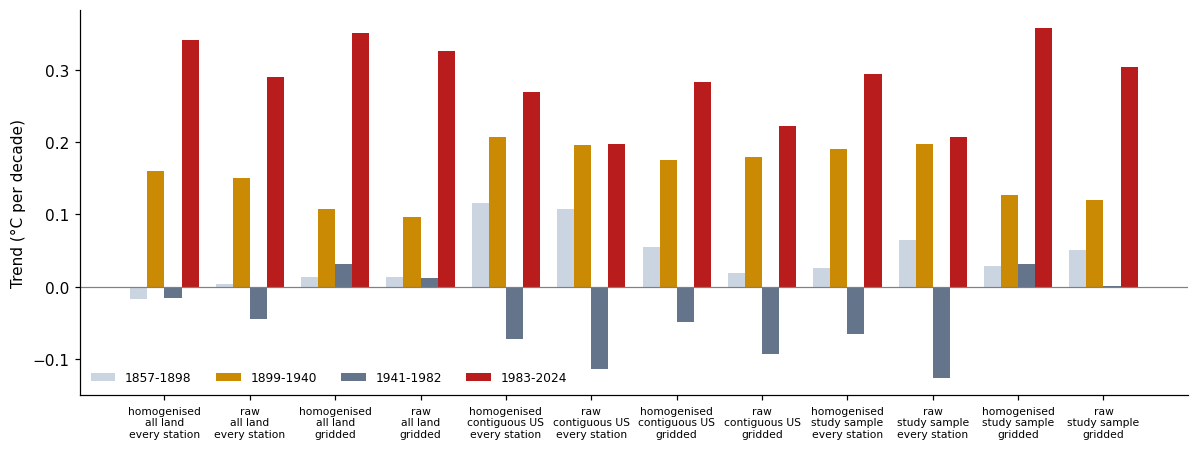

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(table))
for i, (a, b) in enumerate(WINDOWS):
    ax.bar(x + (i - 1.5) * 0.2, table[f"{a}-{b}"], 0.2, label=f"{a}-{b}",
           color=["#cbd5e1", "#ca8a04", "#64748b", "#b91c1c"][i])
ax.set_xticks(x)
ax.set_xticklabels([f"{r.data}\n{r.stations}\n{r.average.replace('_', ' ')}" for r in table.itertuples()], fontsize=7)
ax.axhline(0, color="0.5", lw=0.8)
ax.set_ylabel("Trend (°C per decade)")
ax.legend(frameon=False, fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

Reading it: one group of four bars per way of building the record; within a group, one bar per window, oldest
(light grey) to newest (red). In every group built on corrected data or on area weighting, the red bar is the
tallest.

# Test 2: El Niño

## What ENSO is

Every two to seven years the trade winds over the tropical Pacific weaken, warm water spreads east, and the ocean
releases heat into the air: an **El Niño**. The opposite phase, with strong trade winds and cold water upwelling in
the east, is **La Niña**. Together they are the **El Niño-Southern Oscillation (ENSO)**. An El Niño warms the whole
globe by around 0.1-0.2 °C for a year; 1998, 2016 and 2024 were El Niño years.

ENSO is measured by the **Niño 3.4 index**: the sea-surface temperature anomaly in a box of the central Pacific
(5° N-5° S, 170°-120° W). We use NOAA's ERSSTv5 reconstruction, which goes back to 1854, as served by the KNMI
Climate Explorer. The file has one line per month: a decimal year and the anomaly in °C.

## Why it matters here

ENSO adds noise, and noise near the ends of a short window can tilt its trend. If one window happened to start in
a La Niña and end in an El Niño, its trend would be too steep. Removing ENSO tests whether the window ordering is
real or luck.

In [11]:
nino = pd.read_csv(get("nino34_ersst.dat", "https://climexp.knmi.nl/data/iersst_nino3.4a.dat"),
                   sep=r"\s+", comment="#", names=["t", "anom"])
k = np.round(nino.t * 12).astype(int)
nino.index = pd.to_datetime({"year": k // 12, "month": k % 12 + 1, "day": 1})
lagged = nino.anom.shift(3)                       # global air temperature follows the Pacific by about 3 months
enso = lagged.groupby(lagged.index.year).mean().rename("nino34")
print(enso.loc[[1878, 1998, 2011, 2016, 2023, 2024]].round(2))

1878    1.03
1998    0.91
2011   -0.94
2016    1.21
2023    0.17
2024    0.98
Name: nino34, dtype: float64


The **3-month lag** shifts the index so that, for example, the December peak of an El Niño counts in the following
year, when the air feels it. The printed years are well-known events: strong El Niños in 1878, 1998 and 2016 (and
the 2023 one, felt mostly in 2024) and a La Niña in 2011.

## Removing it

We cannot simply regress temperature on ENSO, because temperature also contains the long forced rise. So we first
take the forced part away with the energy-balance model from the first notebook, then ask how much of what is left
moves with ENSO.

In [12]:
g = pd.read_csv(DATA / "hadcrut5.csv").rename(columns={"Time": "year", "Anomaly (deg C)": "global"}).set_index("year")["global"]
f = pd.read_csv(DATA / "forcing.csv").rename(columns={"Unnamed: 0": "year"})
f["year"] = f.year.astype(int)
f = f.set_index("year").loc[:2024]


def respond(forcing, tau=(4.0, 250.0), q=(0.33, 0.41)):
    """Two-box energy-balance response (K) to a forcing series (W/m2): see notebook 1."""
    out = np.zeros(len(forcing))
    for t_, q_ in zip(tau, q):
        box, a = 0.0, np.exp(-1 / t_)
        for i, F in enumerate(forcing):
            box = box * a + q_ * F * (1 - a)
            out[i] += box
    return pd.Series(out, index=forcing.index)


forced = respond(f.total)
d = pd.DataFrame({"global": g, "forced": forced, "nino34": enso}).loc[1854:2024].dropna()
d["forced"] += (d["global"] - d["forced"]).mean()           # match the baseline
d["left_over"] = d["global"] - d["forced"]
slope = np.polyfit(d.nino34, d.left_over, 1)[0]
d["enso_part"] = slope * (d.nino34 - d.nino34.mean())
d["without_enso"] = d["global"] - d.enso_part
print(f"global temperature moves {slope:.2f} °C per 1 °C of Niño 3.4")
r2 = lambda resid: 1 - (resid ** 2).sum() / ((d["global"] - d["global"].mean()) ** 2).sum()
print(f"share of year-to-year variance explained: forcing {r2(d.left_over):.2f}, forcing + ENSO {r2(d.left_over - d.enso_part):.2f}")

global temperature moves 0.13 °C per 1 °C of Niño 3.4
share of year-to-year variance explained: forcing 0.87, forcing + ENSO 0.92


So a strong El Niño, with Niño 3.4 at +2 °C, adds about a quarter of a degree to that year's global temperature.
Forcing alone explains most of the variance of annual temperature since 1854; adding ENSO explains part of what was
left.

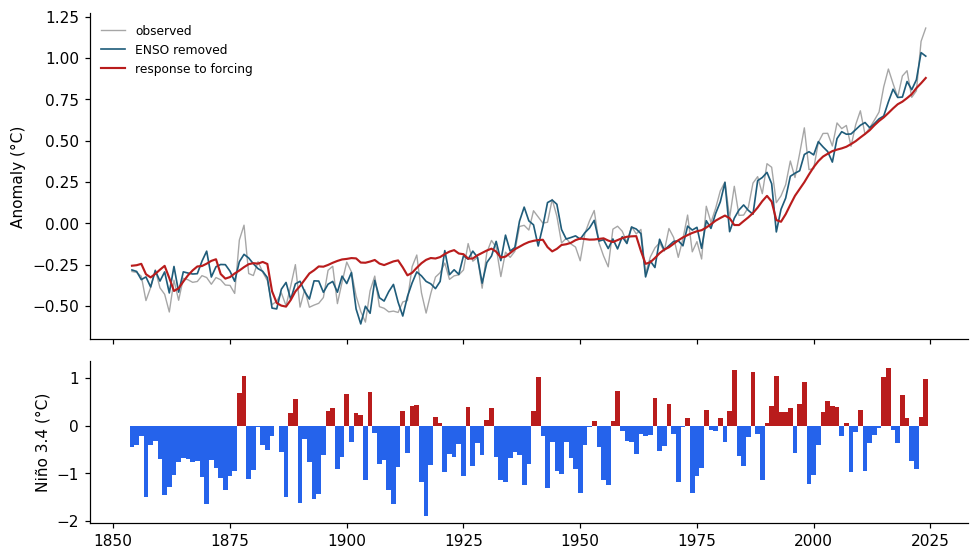

   window  observed  ENSO removed  ENSO's own trend
1857-1898    -0.009        -0.025             0.017
1899-1940     0.101         0.112            -0.011
1941-1982     0.012         0.001             0.011
1983-2024     0.216         0.216             0.000
1910-1945     0.156         0.153             0.003
1976-2024     0.204         0.202             0.002


In [13]:
fig, axs = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axs[0].plot(d.index, d["global"], color="0.65", lw=0.9, label="observed")
axs[0].plot(d.index, d.without_enso, color="#1f5c7a", lw=1.1, label="ENSO removed")
axs[0].plot(d.index, d.forced, color="#b91c1c", lw=1.4, label="response to forcing")
axs[0].set_ylabel("Anomaly (°C)")
axs[0].legend(frameon=False, fontsize=8)
axs[1].bar(d.index, d.nino34, color=np.where(d.nino34 > 0, "#b91c1c", "#2563eb"), width=1)
axs[1].set_ylabel("Niño 3.4 (°C)")
plt.tight_layout()
plt.show()

rows = []
for a, b in WINDOWS + [(1910, 1945), (1976, 2024)]:
    w = d.loc[a:b]
    rows.append({"window": f"{a}-{b}", "observed": trend(w.index, w["global"])[0],
                 "ENSO removed": trend(w.index, w.without_enso)[0], "ENSO's own trend": trend(w.index, w.enso_part)[0]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

Reading it: in the top panel, the blue line (ENSO removed) is smoother than the grey one (observed), with the
spikes of 1878, 1998 and 2016 flattened. The lower panel shows the index itself: red bars El Niño, blue La Niña.
In the table, ENSO's own trend in each window is at most a couple of hundredths of a degree per decade. Removing
it changes no window by more than that, and the ordering of the windows stays the same. ENSO is noise around the
trends, not their cause.

# Test 3: the uncertainty of the record

## 200 histories instead of one

The global temperature of 1880 is not known exactly: ships measured the sea with buckets of different kinds,
much of the world had no station, and the corrections themselves are uncertain. The Met Office represents this
with an **ensemble**: 200 complete global temperature histories, each consistent with the measurements and their
known errors. Where the evidence is solid, the 200 agree; where it is thin, they spread. The file also gives a
**coverage uncertainty**: the extra error from the parts of the globe no one measured.

The honest way to use an ensemble is to repeat the whole calculation on every member and look at the spread of
results, rather than calculating once on the average.

In [14]:
ens = pd.read_csv(get("hadcrut5_ensemble.csv", "https://www.metoffice.gov.uk/hadobs/hadcrut5/data/HadCRUT.5.0.2.0/"
                      "analysis/diagnostics/HadCRUT.5.0.2.0.analysis.ensemble_series.global.annual.csv")).set_index("Time")
members = ens.filter(like="Realization")
coverage = ens["Coverage uncertainty (1 sigma)"]
print(members.shape, "| members for 1880:", members.loc[1880].round(2).values[:5], "...")
print(f"spread (sd) of members: 1880 {members.loc[1880].std():.3f} °C, 2020 {members.loc[2020].std():.3f} °C")

(176, 200) | members for 1880: [-0.36 -0.31 -0.34 -0.38 -0.26] ...
spread (sd) of members: 1880 0.054 °C, 2020 0.017 °C


The members disagree about 1880 by several times more than about 2020. For each window and each of the 200
members we compute the trend three times over, adding the other two sources of error as random draws:

1. the member itself (measurement and bias uncertainty);
2. plus random noise of the size of the coverage uncertainty, year by year;
3. plus a random error of the size of the trend's own standard error (the regression uncertainty).

This is a **Monte Carlo** calculation: instead of deriving the combined error with formulas, we simulate it.

In [15]:
rng = np.random.default_rng(1)
draws = {}
for a, b in WINDOWS:
    yrs = np.arange(a, b + 1)
    out = []
    for c in members.columns:
        y = members.loc[a:b, c].values + rng.normal(0, coverage.loc[a:b].values)
        s, se = trend(yrs, y)
        out.append(s + rng.normal(0, se))
    draws[f"{a}-{b}"] = np.array(out)
summary = pd.DataFrame({w: {"median": np.median(v), "2.5 %": np.percentile(v, 2.5), "97.5 %": np.percentile(v, 97.5)}
                        for w, v in draws.items()}).T.round(3)
print(summary)
p = np.mean(draws["1983-2024"] > rng.permutation(draws["1899-1940"]))
print(f"\nshare of draws in which 1983-2024 warmed faster than 1899-1940: {p:.3f}")

           median  2.5 %  97.5 %
1857-1898  -0.009 -0.062   0.039
1899-1940   0.100  0.051   0.156
1941-1982   0.008 -0.060   0.071
1983-2024   0.217  0.186   0.244

share of draws in which 1983-2024 warmed faster than 1899-1940: 1.000


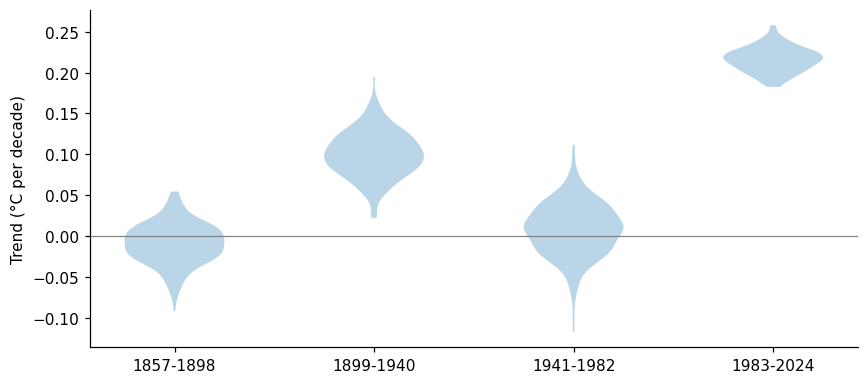

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.violinplot(list(draws.values()), showextrema=False)
ax.set_xticks(range(1, len(draws) + 1))
ax.set_xticklabels(draws.keys())
ax.axhline(0, color="0.5", lw=0.8)
ax.set_ylabel("Trend (°C per decade)")
plt.tight_layout()
plt.show()

Reading it: a **violin plot** shows the shape of a distribution: wide where many draws fall, thin where few do.
The two older violins are wider, because the old record is less certain. But the 1983-2024 violin does not
overlap the 1899-1940 one at all: in every one of the 200 draws, recent warming is the faster.

# Test 4: what climate models say

## What a climate model is

A **global climate model** solves the equations of motion, heat and water for the atmosphere and ocean on a grid
of boxes around the Earth, typically 100 km wide, stepping forward 20-30 minutes at a time. Modelling centres in
many countries contribute runs to a common experiment, the **Coupled Model Intercomparison Project (CMIP6)**. In
the *historical* experiment each model is given the same observed forcing since 1850 (greenhouse gases, aerosols,
the Sun, volcanoes); after 2014 we continue with a middle scenario, **SSP2-4.5**.

A model also makes its own weather, including its own El Niños, but at random times. So no model should match the
observed wiggles year by year; across many models, the wiggles cancel and what remains is the forced response.
The spread across models shows how much forcing plus chance can produce.

## Getting model output from the cloud

The Pangeo project keeps CMIP6 output on Google Cloud as **Zarr** stores: data cut into small chunks, each chunk
a separate file, so a program can read just the variable and years it needs over plain HTTPS. A catalogue file
lists every store. We use the monthly near-surface air temperature (`tas`, table `Amon`) of the first run
(`r1i1p1f1`) of each model that has both experiments. This needs the `xarray`, `zarr` and `fsspec` packages.

To keep the notebook fast we read eight models here. The full analysis behind the essay used all 34.

In [17]:
import xarray as xr

cat = pd.read_csv(get("pangeo-cmip6.csv", "https://storage.googleapis.com/cmip6/pangeo-cmip6.csv"))
q = cat[cat.experiment_id.isin(["historical", "ssp245"]) & (cat.table_id == "Amon") & (cat.variable_id == "tas")
        & (cat.member_id == "r1i1p1f1")]
both = sorted(set(q[q.experiment_id == "historical"].source_id) & set(q[q.experiment_id == "ssp245"].source_id))
print(len(both), "models with both experiments, e.g.", both[:6])
MODELS = ["ACCESS-CM2", "CanESM5", "EC-Earth3", "GFDL-ESM4", "IPSL-CM6A-LR", "MIROC6", "MPI-ESM1-2-LR", "MRI-ESM2-0"]


def global_mean(store):
    ds = xr.open_zarr(store.replace("gs://", "https://storage.googleapis.com/"), consolidated=True)
    weights = np.cos(np.deg2rad(ds.lat))                         # the same cos(latitude) area weight as for stations
    return ds.tas.weighted(weights).mean(("lat", "lon")).groupby("time.year").mean().to_series()


models = {}
for m in MODELS:
    cache = DATA / f"cmip6_{m}.csv"
    if not cache.exists():
        parts = [global_mean(q[(q.source_id == m) & (q.experiment_id == e)].sort_values("version").zstore.iloc[-1])
                 for e in ("historical", "ssp245")]
        s = pd.concat([parts[0], parts[1][parts[1].index > parts[0].index.max()]]).loc[1850:2024]
        s.to_csv(cache)
    s = pd.read_csv(cache, index_col=0).iloc[:, 0]
    models[m] = s - s.loc[1850:1900].mean()                     # anomaly from the pre-industrial period
models = pd.DataFrame(models)
print(models.loc[[1850, 1950, 2024]].round(2))

34 models with both experiments, e.g. ['ACCESS-CM2', 'AWI-CM-1-1-MR', 'BCC-CSM2-MR', 'CAMS-CSM1-0', 'CAS-ESM2-0', 'CESM2-WACCM']
      ACCESS-CM2  CanESM5  EC-Earth3  GFDL-ESM4  IPSL-CM6A-LR  MIROC6  MPI-ESM1-2-LR  MRI-ESM2-0
year                                                                                            
1850        0.10     0.09      -0.08      -0.08         -0.21   -0.09          -0.04        0.06
1950        0.02     0.44      -0.25       0.18          0.26    0.19           0.28        0.39
2024        1.38     2.05       1.60       1.18          1.73    1.20           1.40        1.36


A model's own temperature can be a degree or two off the real one, so, like the stations, each is converted to
an anomaly, here from its 1850-1900 mean. The observations are put on the same baseline.

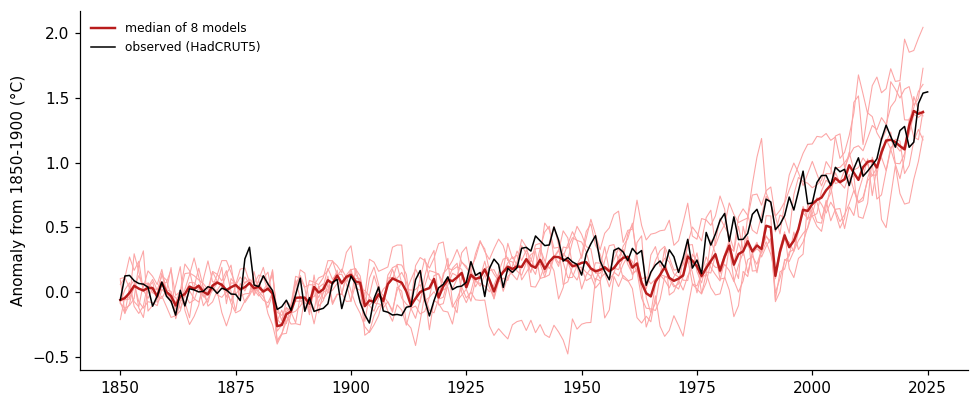

   window  observed  models lowest  models median  models highest
1857-1898    -0.009         -0.060         -0.010           0.036
1899-1940     0.101         -0.034          0.052           0.083
1941-1982     0.012         -0.027         -0.002           0.069
1983-2024     0.216          0.176          0.276           0.418
1910-1945     0.156         -0.083          0.074           0.156


In [18]:
obs = g - g.loc[1850:1900].mean()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(models.index, models, color="#fca5a5", lw=0.7)
ax.plot(models.index, models.median(axis=1), color="#b91c1c", lw=1.6, label="median of 8 models")
ax.plot(obs.index, obs, color="k", lw=1, label="observed (HadCRUT5)")
ax.set(ylabel="Anomaly from 1850-1900 (°C)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

rows = []
for a, b in WINDOWS + [(1910, 1945)]:
    yrs = np.arange(a, b + 1)
    tr = [trend(yrs, models.loc[a:b, m].values)[0] for m in models]
    rows.append({"window": f"{a}-{b}", "observed": trend(yrs, obs.loc[a:b].values)[0],
                 "models lowest": min(tr), "models median": np.median(tr), "models highest": max(tr)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

Reading it: the thin pink lines are single models, each with its own random weather; the red line is their
median, the black line the observations. The models, given only the forcing, rise slowly to 1940, flatten in
mid-century as aerosol pollution grows, and climb steeply after 1975, just as observed.

In the table, the models put the fastest warming in the most recent window, every one of them. For 1910-1945 the
observed trend is at or above the top of the model range: the models reproduce part of the early warming from
forcing (the Sun brightened and there were few large eruptions), and the rest was unforced variability in the
real climate, as earlier studies have found. That is the one period where the study's instinct, that something
other than CO₂ was at work, is partly right; it does not carry over to the last 40 years, when every model and
every record agree.

# What the four tests show

| Test | What it changes | Does the recent window still warm fastest? |
|---|---|---|
| Stations | raw or homogenised; every station equal or area-weighted; all land, US, or the study's own stations | Yes, whenever the data are homogenised or area-weighted. Only raw data averaged station by station make the two windows similar |
| El Niño | removes the largest natural year-to-year swing | Yes; no window changes by more than 0.02 °C per decade |
| Record uncertainty | all 200 HadCRUT5 histories plus coverage and regression error | Yes, in every draw |
| Climate models | 34 models given the observed forcing (8 here) | Yes, in every model |

# Recording what the run used

In [19]:
print(json.dumps({"numpy": np.__version__, "pandas": pd.__version__, "xarray": xr.__version__,
                  "data_mb": {p.name: round(p.stat().st_size / 1e6, 1) for p in sorted(DATA.iterdir()) if p.is_file()},
                  "minutes": round((time.time() - t_start) / 60, 1)}, indent=1))

{
 "numpy": "2.0.1",
 "pandas": "2.2.3",
 "xarray": "2025.4.0",
 "data_mb": {
  "cmip6_ACCESS-CM2.csv": 0.0,
  "cmip6_CanESM5.csv": 0.0,
  "cmip6_EC-Earth3.csv": 0.0,
  "cmip6_GFDL-ESM4.csv": 0.0,
  "cmip6_IPSL-CM6A-LR.csv": 0.0,
  "cmip6_MIROC6.csv": 0.0,
  "cmip6_MPI-ESM1-2-LR.csv": 0.0,
  "cmip6_MRI-ESM2-0.csv": 0.0,
  "conus.csv": 0.0,
  "forcing.csv": 0.1,
  "ghcnd-inventory.txt": 36.4,
  "ghcnm_qcf.tar.gz": 44.2,
  "ghcnm_qcf_annual.csv": 33.3,
  "ghcnm_qcu.tar.gz": 46.0,
  "ghcnm_qcu_annual.csv": 35.4,
  "hadcrut5.csv": 0.0,
  "hadcrut5_ensemble.csv": 0.4,
  "nino34_ersst.dat": 0.1,
  "owid_co2.csv": 14.4,
  "pangeo-cmip6.csv": 80.8
 },
 "minutes": 0.5
}
